In [53]:
import pandas as pd
import numpy as np

df = pd.read_csv("./ia_tweets.csv")

df.head()

,ID,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_has_extended_profile,user_is_translator,user_protected,user_default_profile
0,0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,1,0,0,0
1,1,"@alvaropons Eso es imposible. Y sí, va a gener...",N,1,0,685,851,169490,128555,0,1,0,0,1
2,2,@alvaropons Lo disruptivo es que tras años de ...,NEU,1,0,685,851,169490,128555,0,1,0,0,1
3,3,"@alvaropons ¿""Prohibición del uso comercial de...",N,0,0,4877,538,6123,3156,0,1,0,0,0
4,4,@santoroydonoso Cómo se está estudiando prohib...,NEU,0,0,15936,2395,66945,68578,0,1,0,0,0


In [54]:
df.dtypes

ID                           int64
text                           str
polarity                       str
favorite_count               int64
retweet_count                int64
user_followers_count         int64
user_friends_count           int64
user_favourites_count        int64
user_statuses_count          int64
user_verified                int64
user_has_extended_profile    int64
user_is_translator           int64
user_protected               int64
user_default_profile         int64
dtype: object

In [55]:
from langdetect import detect, DetectorFactory, LangDetectException

DetectorFactory.seed = 0


def idioma(texto):
    try:
        return detect(str(texto))
    except LangDetectException:
        return "es"


df['idioma'] = df['text'].map(idioma)

df = df[df["idioma"] == "es"]

df = df.drop(columns=["ID","user_has_extended_profile", "user_is_translator", "user_protected", "idioma"])

print("Tweets conservados:", len(df))

Tweets conservados: 3660


In [56]:
def filtrar_por_polaridad(field):
    return df[df["polarity"] == field]

cant_negativos = len(filtrar_por_polaridad("N"))
cant_neutros = len(filtrar_por_polaridad("NEU"))
cant_positivos =  len(filtrar_por_polaridad("P"))

print('Cantidad de tweets: ', len(df))
print('Tweets Negativos: ', cant_negativos, ', Neutros' , cant_neutros,', Positivos', cant_positivos)

# Cantidad de datos desbalanceada, se tiene mucho mas datos neutros que negativos o positivos.

Cantidad de tweets:  3660
Tweets Negativos:  551 , Neutros 2417 , Positivos 692


In [57]:
cantidad_na = df.isna().sum()
print(cantidad_na)

#(cantidad_negativos_columna("favorite_count"))

# No hay nulls o valores

text                     0
polarity                 0
favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


In [58]:
cantidad_negativos = (df.select_dtypes(include='number') < 0).sum()
print(cantidad_negativos)

favorite_count           0
retweet_count            0
user_followers_count     0
user_friends_count       0
user_favourites_count    0
user_statuses_count      0
user_verified            0
user_default_profile     0
dtype: int64


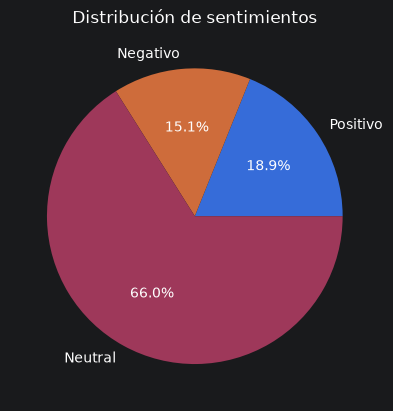

In [59]:
import matplotlib.pyplot as plt

# Datos
clases = ['Positivo', 'Negativo', 'Neutral']
cantidades = [cant_positivos, cant_negativos, cant_neutros]

# Crear gráfico
plt.pie(cantidades, labels=clases, autopct='%1.1f%%')
plt.title('Distribución de sentimientos')
plt.show()

4.1519125683060105
2243
0


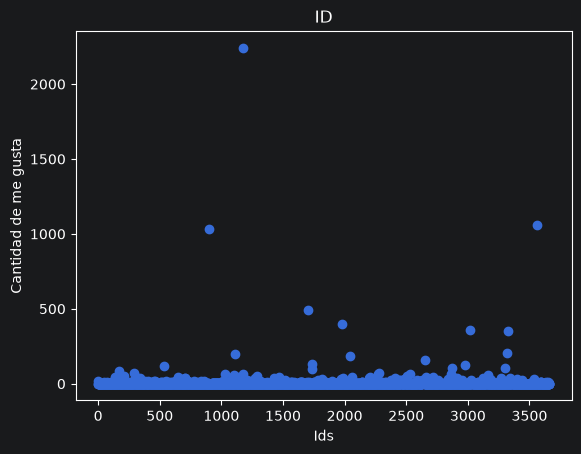

In [60]:
print(df["favorite_count"].mean())
print(df["favorite_count"].max())
print(df["favorite_count"].min())

plt.scatter(range(0,len(df)), df['favorite_count'])

plt.xlabel('Ids')
plt.ylabel('Cantidad de me gusta')
plt.title('ID')

plt.show()

0.9606557377049181
502
0


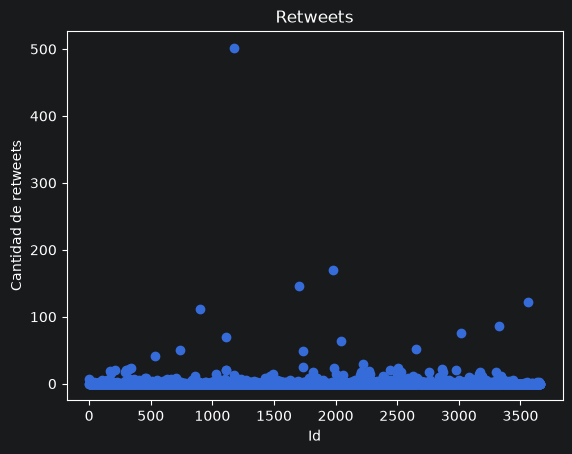

In [61]:
print(df["retweet_count"].mean())
print(df["retweet_count"].max())
print(df["retweet_count"].min())

plt.scatter(range(0,len(df)), df['retweet_count'])

plt.xlabel('Id')
plt.ylabel('Cantidad de retweets')
plt.title('Retweets')

plt.show()

Cantidad de tweets positivo con interaccion:  172
Cantidad de tweets negativos con interaccion:  139
Media de interacciones en positivos:  6.726878612716763
Media de interacciones en negativos:  3.8747731397459164


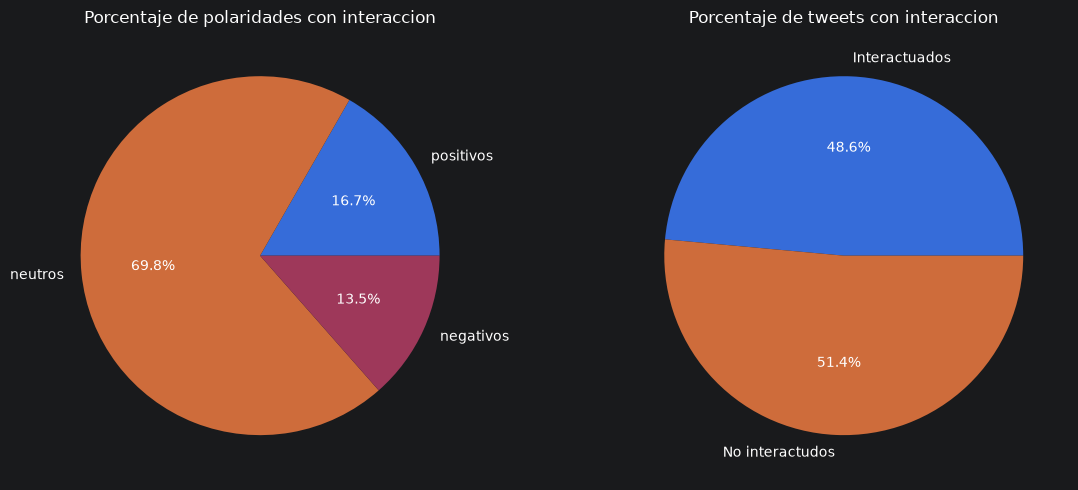

In [62]:
df['tweet_interactions'] = df['favorite_count'] + df['retweet_count']

tweets_con_interaccion = (df['tweet_interactions'] > 0).sum()
tweets_sin_interaccion = (df['tweet_interactions'] == 0).sum()

positivos_con_interaccion = (df[df['polarity'] == 'P']['tweet_interactions'] > 1).sum()
neutros_con_interaccion = (df[df['polarity'] == 'NEU']['tweet_interactions'] > 1).sum()
negativos_con_interaccion = (df[df['polarity'] == 'N']['tweet_interactions'] > 1).sum()
interaccion_positivos_media = df[df['polarity'] == 'P']['tweet_interactions'].mean()
interaccion_negativos_media = df[df['polarity'] == 'N']['tweet_interactions'].mean()

print("Cantidad de tweets positivo con interaccion: ", positivos_con_interaccion)
print("Cantidad de tweets negativos con interaccion: ", negativos_con_interaccion)
print("Media de interacciones en positivos: ", interaccion_positivos_media)
print("Media de interacciones en negativos: ", interaccion_negativos_media)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].pie([positivos_con_interaccion, neutros_con_interaccion, negativos_con_interaccion], labels=["positivos", "neutros", "negativos"], autopct='%1.1f%%')
ax[0].set_title('Porcentaje de polaridades con interaccion')

ax[1].pie([tweets_con_interaccion, tweets_sin_interaccion],
  labels=["Interactuados", "No interactudos"], autopct='%1.1f%%')
ax[1].set_title('Porcentaje de tweets con interaccion')

plt.tight_layout()
plt.show()

In [63]:
 #text
#polarity
#favorite_count
#retweet_count
#user_followers_count
#user_friends_count
#user_favourites_count         TEST (Likes que dio)
#user_statuses_count           TEST (Publicaciones y comentarios suyos)
#user_verified                 TEST
#user_default_profile          TEST (Pagina de perfil default)

import unicodedata

def contar_emojis(texto):
    return sum(1 for caracter in str(texto) if unicodedata.category(caracter) == 'So')

df["length"] = df['text'].apply(lambda texto: len(texto.split()))
df["hashtag_count"] = df['text'].apply(lambda texto: texto.count('#'))
df["mention_count"] = df['text'].apply(lambda texto: texto.count('@'))
df["url_count"] = df['text'].apply(lambda texto: texto.count('http'))
df["punctuation_count"] = df['text'].apply(lambda texto: texto.count('?') + texto.count('!'))
df['emoji_count'] = df['text'].apply(contar_emojis)

# :url: :mencion:

#Campos extra
#Longitud (palabras)
#Cantidad de hashtags
#Cantidad de usuarios mencionados
#Cantidad de emojis
#Cantidad de urls
#Cantidad de signos de exclamacion/interrogacion

In [64]:
import re
import unicodedata

URL_RE = re.compile(r"https?://\S+|www\.\S+", re.IGNORECASE)
MENTION_RE = re.compile(r"@\w+")
HASHTAG_RE = re.compile(r"#(\w+)")


def _separar_hashtag(match):
    """#InteligenciaArtificial -> Inteligencia Artificial."""
    palabra = match.group(1)
    return " " + re.sub(r"(?<=[a-záéíóúüñ])(?=[A-ZÁÉÍÓÚÑ])", " ", palabra) + " "


def normalizar_texto(texto):
    """Normaliza sin perder informacion util para el modelo.

    - NFC conserva tildes y enes en una forma canonica.
    - URLs, menciones y hashtags se reemplazan por tokens explicitos.
    - El hashtag conserva su palabra para no perder el tema del tweet.
    """
    texto = unicodedata.normalize("NFC", str(texto))
    texto = URL_RE.sub(" URL ", texto)
    texto = MENTION_RE.sub(" MENCION ", texto)
    texto = HASHTAG_RE.sub(_separar_hashtag, texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto


df["text"] = df["text"].map(normalizar_texto)

df.head()

,text,polarity,favorite_count,retweet_count,user_followers_count,user_friends_count,user_favourites_count,user_statuses_count,user_verified,user_default_profile,tweet_interactions,length,hashtag_count,mention_count,url_count,punctuation_count,emoji_count
0,Comentaba en una charla sobre IA que el proble...,N,21,7,15936,2395,66945,68578,0,0,28,44,0,0,1,0,0
1,"MENCION Eso es imposible. Y sí, va a generar u...",N,1,0,685,851,169490,128555,0,1,1,41,0,1,0,0,0
2,MENCION Lo disruptivo es que tras años de deci...,NEU,1,0,685,851,169490,128555,0,1,1,39,0,1,0,0,0
3,"MENCION ¿""Prohibición del uso comercial de las...",N,0,0,4877,538,6123,3156,0,0,0,17,0,1,0,1,0
4,MENCION Cómo se está estudiando prohibir chatG...,NEU,0,0,15936,2395,66945,68578,0,0,0,39,0,1,0,1,0


In [65]:
import emoji
from emosent import get_emoji_sentiment_rank

def emoji_features(text):
    scores = []
    for e in emoji.emoji_list(str(text)):
        try:
            rank = get_emoji_sentiment_rank(e["emoji"])
        except KeyError:
            rank = None
        if rank is not None:
            scores.append(rank["sentiment_score"])
    if not scores:
        return 0.0, 0, 0
    return (
        sum(scores) / len(scores),
        sum(s > 0.1 for s in scores),
        sum(s < -0.1 for s in scores),
    )

df[["emoji_score", "emoji_pos", "emoji_neg"]] = df["text"].apply(
    lambda t: pd.Series(emoji_features(t))
)

In [66]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["polarity"])
y = df["polarity"]

# 60% para train y 40% para test y validacion
X_train, X_test_val, y_train, y_test_val = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Segunda división: separar test y validación
X_test, X_val, y_test, y_val = train_test_split(
    X_test_val, y_test_val,
    test_size=0.5,
    random_state=42,
    stratify=y_test_val
)

print(len(X_train)/len(df))

0.6


In [67]:
# Las features numericas se escalan dentro del Pipeline (ver preprocessor).
# Asi se evita el doble escalado y que el scaler vea datos de test.
number_columns = [
    "favorite_count", "retweet_count",
    "user_followers_count", "user_friends_count",
    "user_favourites_count", "user_statuses_count",
    "tweet_interactions",
    "hashtag_count", "mention_count",
    "length", "url_count", "punctuation_count", "emoji_count",
    "emoji_score", "emoji_pos", "emoji_neg"
]

#y_train = pd.get_dummies(y_train, columns=["polarity"], dtype=int)

X_train.head()
y_train.head()

1468    NEU
3145    NEU
2137    NEU
3883    NEU
2562    NEU
Name: polarity, dtype: str

### Preprocesamiento de texto en español

Decisiones aplicadas a todas las representaciones de texto:

- **Detección de idioma:** se mantiene `langdetect` (multilingüe). Se protege con `try/except` para no descartar textos cortos o sin letras. Limitación: algunos tweets cortos en español pueden detectarse como catalán/portugués y perderse.
- **Tokenización:** `nltk.word_tokenize(..., language='spanish')`; no se usa el modelo de inglés.
- **Stemming:** `SnowballStemmer('spanish')` (el Porter de NLTK es solo inglés).
- **Lematización:** `simplemma` con `lang='es'` (el WordNet de NLTK es solo inglés).
- **Stopwords:** lista de NLTK en español, **conservando negaciones** (`no`, `ni`, `sin`, `nada`) e intensificadores (`muy`, `mucho`, `poco`, `más`, `pero`) porque cambian el sentimiento.
- **Puntuación:** además de `string.punctuation`, se eliminan `¿ ¡ « » – — … “ ”`.
- **Emojis:** se convierten a palabras en español con `emoji.demojize(..., language='es')` y se conserva `emoji_count` como feature numérica.
- **Hashtags:** se conserva la palabra y se separa CamelCase (`#InteligenciaArtificial` → `inteligencia artificial`).
- **Embeddings:** `paraphrase-multilingual-MiniLM-L12-v2` es multilingüe y cubre español; recibe limpieza mínima porque su tokenizador maneja mayúsculas, puntuación y contexto. Alternativas específicas de español para comparar: `hiiamsid/sentence_similarity_spanish_es` y `PlanTL-GOB-ES/roberta-base-bne`.
- **TF-IDF:** se ajusta solo con train, con n-gramas (1,2) para capturar negaciones y `min_df`/`max_df` para reducir ruido.


In [68]:
from sklearn.base import BaseEstimator, TransformerMixin
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize
import string
# Requiere: pip install simplemma emoji
import emoji
import simplemma

nltk.download('stopwords', quiet=True)
nltk.download('punkt_tab', quiet=True)

# Stopwords en espanol, excepto negaciones e intensificadores:
# son senal de sentimiento y no deben eliminarse.
NEGACIONES = {"no", "ni", "sin", "nada", "nunca", "tampoco", "jamas", "jamás"}
INTENSIFICADORES = {"muy", "mucho", "poco", "mas", "más", "pero"}
STOP_WORDS = set(stopwords.words('spanish')) - NEGACIONES - INTENSIFICADORES
PROTEGIDAS = NEGACIONES | INTENSIFICADORES

# string.punctuation es ASCII: agregamos la puntuacion propia del espanol.
PUNTUACION = set(string.punctuation) | set("¿¡«»–—…“”‘’")
PUNTUACION_STR = "".join(sorted(PUNTUACION))


def demojizar(texto):
    """Convierte emojis en palabras en espanol: 😂 -> cara llorando de risa."""
    texto = emoji.demojize(str(texto), language="es", delimiters=(" ", " "))
    return texto.replace("_", " ")


class TextCleaner(BaseEstimator, TransformerMixin):
    def __init__(self, method=None):
        self.method = method

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        stemmer = SnowballStemmer('spanish')
        clean_X = []
        for text in X:
            # 0. Normalizacion (idempotente: la columna ya viene normalizada)
            text = normalizar_texto(text)

            # 1. Emojis a texto y minusculas
            text = demojizar(text).lower()

            # 2. Tokenizacion con el modelo de espanol (no el de ingles)
            tokens = word_tokenize(text, language='spanish')

            # 3. Limpieza de puntuacion (incluye ¿ ¡ « » …) y tokens vacios
            tokens = [t.strip(PUNTUACION_STR) for t in tokens]
            tokens = [t for t in tokens if t and any(c.isalnum() for c in t)]

            # 4. Stopwords en espanol conservando negaciones e intensificadores
            tokens = [t for t in tokens if t not in STOP_WORDS]

            # 5. Reduccion a raiz: stemming o lematizacion en espanol
            # No reducimos negaciones ni intensificadores: cambian el sentido.
            if self.method == 'stem':
                tokens = [t if t in PROTEGIDAS else stemmer.stem(t) for t in tokens]
            elif self.method == 'lemma':
                tokens = [t if t in PROTEGIDAS else simplemma.lemmatize(t, lang='es')
                          for t in tokens]

            clean_X.append(" ".join(tokens))
        return clean_X


class LightCleaner(BaseEstimator, TransformerMixin):
    """Limpieza minima para modelos de embeddings multilingues.

    El tokenizador del transformer ya maneja mayusculas, puntuacion y contexto;
    solo normalizamos URLs/menciones/hashtags y pasamos emojis a texto.
    """

    def __init__(self, demojizar_texto=True):
        self.demojizar_texto = demojizar_texto

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        clean_X = []
        for text in X:
            text = normalizar_texto(text)
            if self.demojizar_texto:
                text = demojizar(text)
            text = re.sub(r"\s+", " ", text).strip()
            clean_X.append(text)
        return clean_X

In [69]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

# TF-IDF en espanol: se ajusta SOLO con train para no filtrar informacion de test.
tfidf_pipe = Pipeline([
    ("cleaner", TextCleaner(method="lemma")),
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents=None,          # probar 'unicode' como experimento
        ngram_range=(1, 2),          # captura negaciones: "no es", "muy bueno"
        min_df=3,
        max_df=0.9,
        sublinear_tf=True,
        token_pattern=r"(?u)\b\w+\b",
    )),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

tfidf_pipe.fit(X_train["text"], y_train)

for nombre, X_, y_ in [("train", X_train, y_train),
                       ("val", X_val, y_val),
                       ("test", X_test, y_test)]:
    pred = tfidf_pipe.predict(X_["text"])
    print(f"F1 macro {nombre}: {f1_score(y_, pred, average='macro'):.4f}")

F1 macro train: 0.8808
F1 macro val: 0.6041
F1 macro test: 0.6222


In [70]:
from sentence_transformers import SentenceTransformer  # <- Estandar para Embeddings


class EmbeddingTransformer(BaseEstimator, TransformerMixin):
    # Alternativas especificas de espanol para comparar:
    #   - hiiamsid/sentence_similarity_spanish_es
    #   - PlanTL-GOB-ES/roberta-base-bne (requiere mean pooling)
    # Cache a nivel de CLASE: sobrevive a los clones que arma GridSearchCV
    # Clave: (nombre_del_modelo, texto) -> vector
    # El modelo es multilingue (incluye espanol) y trae su propio tokenizador.
    _cache = {}

    def __init__(self, model_name='paraphrase-multilingual-MiniLM-L12-v2'):
        self.model_name = model_name

    def fit(self, X, y=None):
        # Cargamos el modelo aqui para evitar errores de serializacion
        if not hasattr(self, "model_"):
            self.model_ = SentenceTransformer(self.model_name)
        return self

    def transform(self, X):
        # Permite usar el transformador aunque se lo llame sin fit previo.
        if not hasattr(self, "model_"):
            self.fit(X)

        # Convertimos la lista de textos en una matriz de vectores (Embeddings)
        # Esto implementa implicitamente el "Mean Pooling"
        # Solo calculamos los textos que aun no estan en la cache
        texts = list(X)
        faltantes = [t for t in texts if (self.model_name, t) not in self._cache]
        if faltantes:
            vectores = self.model_.encode(faltantes, show_progress_bar=False)
            for t, v in zip(faltantes, vectores):
                self._cache[(self.model_name, t)] = v
        return np.array([self._cache[(self.model_name, t)] for t in texts])

embedding = EmbeddingTransformer()

In [71]:
# Carga el modelo una sola vez. No aprende parametros: solo cachea textos.
embedding.fit(X_train["text"])

26296 | INFO | No device provided, using cpu
26296 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
26296 | WARNING | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
26296 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/modules.json?%2Fsentence-transformers%2Fparaphrase-multilingual-MiniLM-L12-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22f7640f94e81bb7f4f04daf1668850b38763a13d9%22 "HTTP/1.1 200 OK"
26296 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
26296 | INFO | HTTP Request: HEAD https://huggingface.co/api

,model_name,'paraphrase-multilingual-MiniLM-L12-v2'
Name,Type,Value
model_,SentenceTransformer,SentenceTrans...mpt': True}) )


In [72]:
def build_model(meta, units=512, n_layers=1, dropout=0.3,
                activation="sigmoid", learning_rate=1e-3):
    model = keras.Sequential()
    model.add(keras.Input(shape=(meta["n_features_in_"],)))
    for _ in range(n_layers):
        model.add(layers.Dense(units, activation=activation))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(meta["n_classes_"], activation="softmax"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

In [73]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from tensorflow import keras
from tensorflow.keras import layers
from scikeras.wrappers import KerasClassifier

# Train + val juntos: GridSearchCV arma sus propios folds de validacion
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])

X_train_raw = X.loc[X_trval.index]
y_train_raw = y.loc[y_trval.index]

num_cols = number_columns

preprocessor = ColumnTransformer([
    # Embeddings: limpieza minima, el modelo multilingue ya entiende espanol.
    ("text", Pipeline([
        ("cleaner", LightCleaner()),
        ("embedding", EmbeddingTransformer()),
    ]), "text"),
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
])

clf = KerasClassifier(
    model=build_model,
    epochs=5,               # 5 epocas por fold en la busqueda
    batch_size=32,
    verbose=0,
)

pipeline_nn = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", clf),
])

param_grid = {
    "classifier__model__units": [64,128],
    "classifier__model__n_layers": [1,2],
    "classifier__model__dropout": [0.3],
    "classifier__model__activation": ["relu", "tanh", "sigmoid"],
    "classifier__model__learning_rate": [1e-2, 1e-3],
    "classifier__batch_size": [32],
}

grid = GridSearchCV(
    pipeline_nn,
    param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=1,
    verbose=2
)

La busqueda de hiperparametros puede tardar varios minutos. Al ejecutar la celda anterior se imprimen los mejores parametros y el mejor F1 macro de validacion cruzada; no se guarda una salida fija porque depende de la corrida.


In [75]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import f1_score
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
from tensorflow.keras import layers

class MetricasTest(keras.callbacks.Callback):
    """Loguea test_loss / test_accuracy en cada época.

    fit() sólo acepta un validation_data, así que el test se evalúa a mano acá.
    """

    def __init__(self, X, y):
        super().__init__()
        self.X, self.y = X, y

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        proba = self.model.predict(self.X, verbose=0)
        loss = keras.losses.sparse_categorical_crossentropy(self.y, proba)
        logs["test_loss"] = float(np.mean(loss))
        logs["test_accuracy"] = float(np.mean(proba.argmax(axis=1) == self.y))

def curva_complejidad(unidades=(4, 8, 16, 32, 64, 128, 256, 512),
                      epochs=5, seed=42, deep=1):
    f1_all_train, f1_all_val, f1_all_test = [], [], []
    for e in range(1, epochs + 1):
        print("=" * 30)
        print(f"Épocas de entrenamiento: {e}")
        print("-" * 30)

        f1_train, f1_val, f1_test = [], [], []

        for u in unidades:
            keras.utils.set_random_seed(seed)

            clf = KerasClassifier(
                model=build_model,
                model__units=u,
                model__n_layers=deep,
                model__dropout=0.3,
                model__activation="sigmoid",
                model__learning_rate=1e-2,
                epochs=e,
                batch_size=32,
                verbose=0
            )

            pipe = Pipeline([
                ("preprocessor", preprocessor),
                ("classifier", clf),
            ])

            pipe.fit(X_trval, y_trval)

            pred_train = pipe.predict(X_train)
            pred_val = pipe.predict(X_val)
            pred_test = pipe.predict(X_test)

            score_train = f1_score(y_train, pred_train, average="macro")
            score_val = f1_score(y_val, pred_val, average="macro")
            score_test = f1_score(y_test, pred_test, average="macro")

            f1_train.append(score_train)
            f1_val.append(score_val)
            f1_test.append(score_test)
            print(
                f"units={u:>4} | "
                f"F1 train={score_train:.3f} | "
                f"F1 val={score_val:.3f} | "
                f"F1 test={score_test:.3f} | "
                f"brecha={score_train-score_test:+.3f}"
            )

        f1_all_train.append(f1_train)
        f1_all_val.append(f1_val)
        f1_all_test.append(f1_test)

    # --- Un panel por época ---
    ncols = epochs if epochs <= 5 else 4
    nrows = int(np.ceil(epochs / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 4 * nrows),
                             sharex=True, sharey=True, squeeze=False)

    for i in range(epochs):
        ax = axes.flatten()[i]
        ax.plot(unidades, f1_all_train[i], "o-", label="Train")
        ax.plot(unidades, f1_all_val[i], "o-", label="Validación")
        ax.plot(unidades, f1_all_test[i], "o--", label="Test")
        ax.set_xscale("log", base=2)
        ax.set_xlabel("Neuronas en la capa oculta (complejidad)")
        ax.set_ylabel("F1 macro")
        ax.set_title(f"{i + 1} Épocas ")
        ax.legend()

    for ax in axes.flatten()[epochs:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

    return pd.DataFrame([
        {"deep": deep, "epoch": i + 1, "units": u,
         "f1_train": f1_all_train[i][j],
         "f1_val": f1_all_val[i][j],
         "f1_test": f1_all_test[i][j]}
        for i in range(epochs) for j, u in enumerate(unidades)
    ])

26296 | INFO | No device provided, using cpu
26296 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
26296 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/modules.json?%2Fsentence-transformers%2Fparaphrase-multilingual-MiniLM-L12-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22f7640f94e81bb7f4f04daf1668850b38763a13d9%22 "HTTP/1.1 200 OK"
26296 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
26296 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/config_sentence_transformers.json

===== Test =====
Accuracy:            0.7391
Precision (macro):   0.7181
Precision (weighted):0.7326
Recall (macro):      0.5604
F1 (macro):          0.6006
F1 (weighted):       0.7132
ROC-AUC (OvR macro): 0.8506

Reporte por clase:

              precision    recall  f1-score   support

           N       0.72      0.30      0.42       110
         NEU       0.75      0.92      0.82       484
           P       0.69      0.46      0.55       138

    accuracy                           0.74       732
   macro avg       0.72      0.56      0.60       732
weighted avg       0.73      0.74      0.71       732



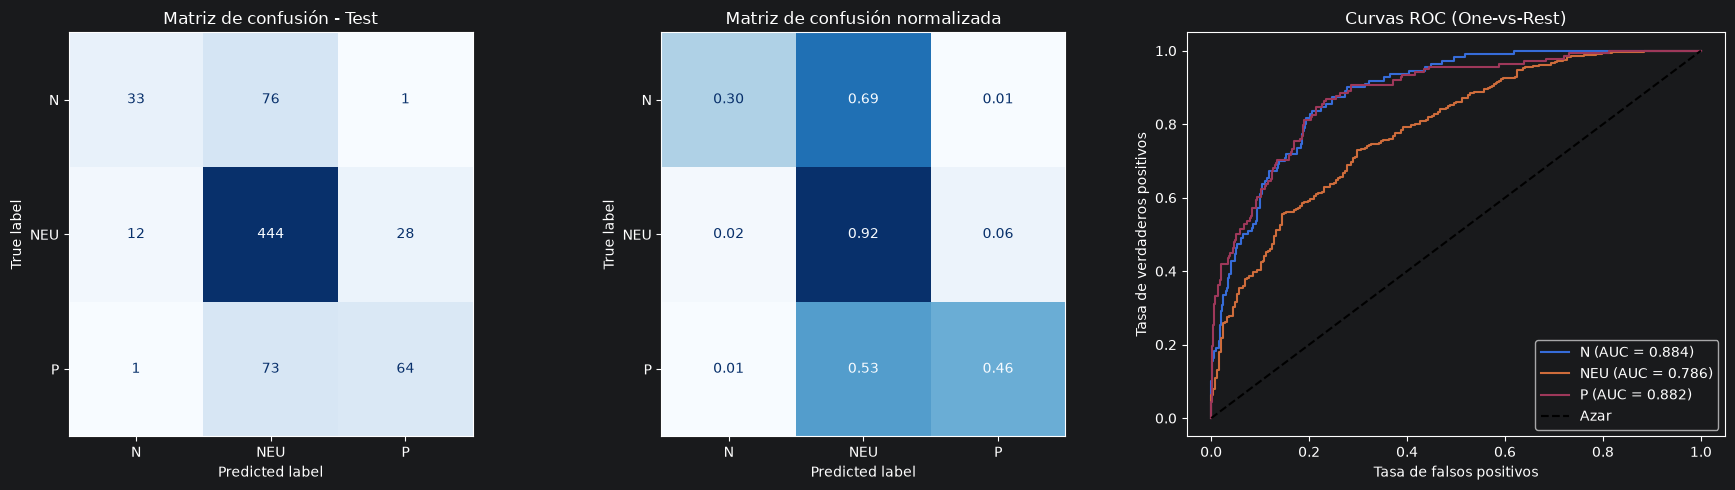

In [82]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from scikeras.wrappers import KerasClassifier


clf = KerasClassifier(
    model=build_model,
    epochs=2,
    batch_size=32,
    verbose=0
)

pl_nn = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", clf),
])

pl_nn.fit(X_train_raw, y_train_raw)

def evaluar(nombre="Test"):
    clases = list(pl_nn.classes_)   # orden real del clasificador
    y_pred = pl_nn.predict(X_test)
    y_proba = pl_nn.predict_proba(X_test)               # columnas en el orden de `clases`

    # ---------- Métricas ----------
    print(f"===== {nombre} =====")
    print(f"Accuracy:            {accuracy_score(y_test, y_pred):.4f}")
    print(f"Precision (macro):   {precision_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
    print(f"Precision (weighted):{precision_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
    print(f"Recall (macro):      {recall_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
    print(f"F1 (macro):          {f1_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
    print(f"F1 (weighted):       {f1_score(y_test, y_pred, average='weighted', zero_division=0):.4f}")
    print(f"ROC-AUC (OvR macro): {roc_auc_score(y_test, y_proba, multi_class='ovr', average='macro', labels=clases):.4f}")
    print("\nReporte por clase:\n")
    print(classification_report(y_test, y_pred, labels=clases, zero_division=0))

    # ---------- Gráficos ----------
    fig, ax = plt.subplots(1, 3, figsize=(18, 5))

    # Matriz de confusión (cantidades)
    cm = confusion_matrix(y_test, y_pred, labels=clases)
    ConfusionMatrixDisplay(cm, display_labels=clases).plot(ax=ax[0], cmap="Blues", colorbar=False)
    ax[0].set_title(f"Matriz de confusión - {nombre}")

    # Matriz de confusión (normalizada por fila = recall por clase)
    cm_norm = confusion_matrix(y_test, y_pred, labels=clases, normalize="true")
    ConfusionMatrixDisplay(cm_norm, display_labels=clases).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".2f")
    ax[1].set_title("Matriz de confusión normalizada")

    # Curvas ROC One-vs-Rest
    y_bin = label_binarize(y_test, classes=clases)
    for i, clase in enumerate(clases):
        fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
        ax[2].plot(fpr, tpr, label=f"{clase} (AUC = {auc(fpr, tpr):.3f})")
    ax[2].plot([0, 1], [0, 1], "k--", label="Azar")
    ax[2].set_xlabel("Tasa de falsos positivos")
    ax[2].set_ylabel("Tasa de verdaderos positivos")
    ax[2].set_title("Curvas ROC (One-vs-Rest)")
    ax[2].legend(loc="lower right")

    plt.tight_layout()
    plt.show()


In [76]:
data = curva_complejidad(deep=1)

Épocas de entrenamiento: 1
------------------------------


26296 | INFO | No device provided, using cpu
26296 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
26296 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/modules.json?%2Fsentence-transformers%2Fparaphrase-multilingual-MiniLM-L12-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22f7640f94e81bb7f4f04daf1668850b38763a13d9%22 "HTTP/1.1 200 OK"
26296 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
26296 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/config_sentence_transformers.json

KeyboardInterrupt: 

In [ ]:
evaluar("Test")

In [83]:
# --- Prueba manual del pipeline ---
tweets = [
    "A veces funciona, a veces no",
    "Nos puede llegar a sacar el trabajo, es un peligro",
    "Es una buena herramienta",
]

# Valores numéricos neutros: mediana del train (no 0)
medianas = X_train_raw[num_cols].median()

entrada = pd.DataFrame({"text": tweets})
for col in num_cols:
    entrada[col] = medianas[col]

clf = pl_nn.named_steps["classifier"]
preds = pl_nn.predict(entrada)
probas = pl_nn.predict_proba(entrada)

resultado = pd.DataFrame(probas, columns=clf.classes_).round(4)
resultado.insert(0, "tweet", tweets)
resultado.insert(1, "prediccion", preds)
print(resultado.to_string(index=False))

                                             tweet prediccion      N    NEU      P
                      A veces funciona, a veces no        NEU 0.2324 0.7498 0.0178
Nos puede llegar a sacar el trabajo, es un peligro          N 0.6620 0.3192 0.0188
                          Es una buena herramienta          P 0.0026 0.2113 0.7860


In [77]:
f1_cols = ["f1_train", "f1_val", "f1_test"]

# La dispersión es el filtro DURO: sólo compiten filas con las tres F1 parejas.
# Recién entre las que pasan se busca el F1 más alto (el mayor de los mínimos).
MAX_RANGO = 0.05          # ajustá acá: 0.03 = más estricto, 0.10 = más laxo

data["f1_min"] = data[f1_cols].min(axis=1)
data["f1_rango"] = data[f1_cols].max(axis=1) - data["f1_min"]
data["f1_std"] = data[f1_cols].std(axis=1)

candidatas = data[data["f1_rango"] <= MAX_RANGO]
print(f"Filas con rango <= {MAX_RANGO}: {len(candidatas)} de {len(data)}")

if candidatas.empty:
    print("\nNinguna fila entra en ese rango. Las más parejas son:")
    data.sort_values("f1_rango").head(10)
else:
    print("\nMejor combinación entre las parejas (mayor mínimo):")
    print(candidatas.loc[[candidatas["f1_min"].idxmax()]].to_string(index=False))

    print(f"\nTop 10 con rango <= {MAX_RANGO}, ordenadas por mínimo:")
    print(candidatas.sort_values(["f1_min", "f1_rango"], ascending=[False, True]).head(10))


NameError: name 'data' is not defined

In [74]:

grid.fit(X_train_raw, y_train_raw)

print("Mejores parametros:", grid.best_params_)
print("Mejor score (CV):", grid.best_score_)
best_model = grid.best_estimator_

Fitting 3 folds for each of 24 candidates, totalling 72 fits


26296 | INFO | No device provided, using cpu
26296 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
26296 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/modules.json?%2Fsentence-transformers%2Fparaphrase-multilingual-MiniLM-L12-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22f7640f94e81bb7f4f04daf1668850b38763a13d9%22 "HTTP/1.1 200 OK"
26296 | INFO | HTTP Request: HEAD https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
26296 | INFO | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2/e8f8c211226b894fcb81acc59f3b34ba3efd5f42/config_sentence_transformers.json

KeyboardInterrupt: 